Imports and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'
PURPLE = '#8E44AD'

from google.colab import files
from pathlib import Path

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Upload hillstrom_scored.csv")
uploaded = files.upload()

df = pd.read_csv('hillstrom_scored.csv')
print(f"Loaded: {len(df):,} rows")
print(f"Columns: {list(df.columns)}")


Upload hillstrom_scored.csv


Saving hillstrom_scored.csv to hillstrom_scored.csv
Loaded: 64,000 rows
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend', 'treatment_mens', 'treatment_womens', 'treatment_any', 'zip_code_enc', 'channel_enc', 'p_if_treated', 'p_if_control', 'uplift_score', 'pred_treated', 'pred_control', 'response_type', 'uplift_decile']


Targeting efficiency: what do we gain by being selective?

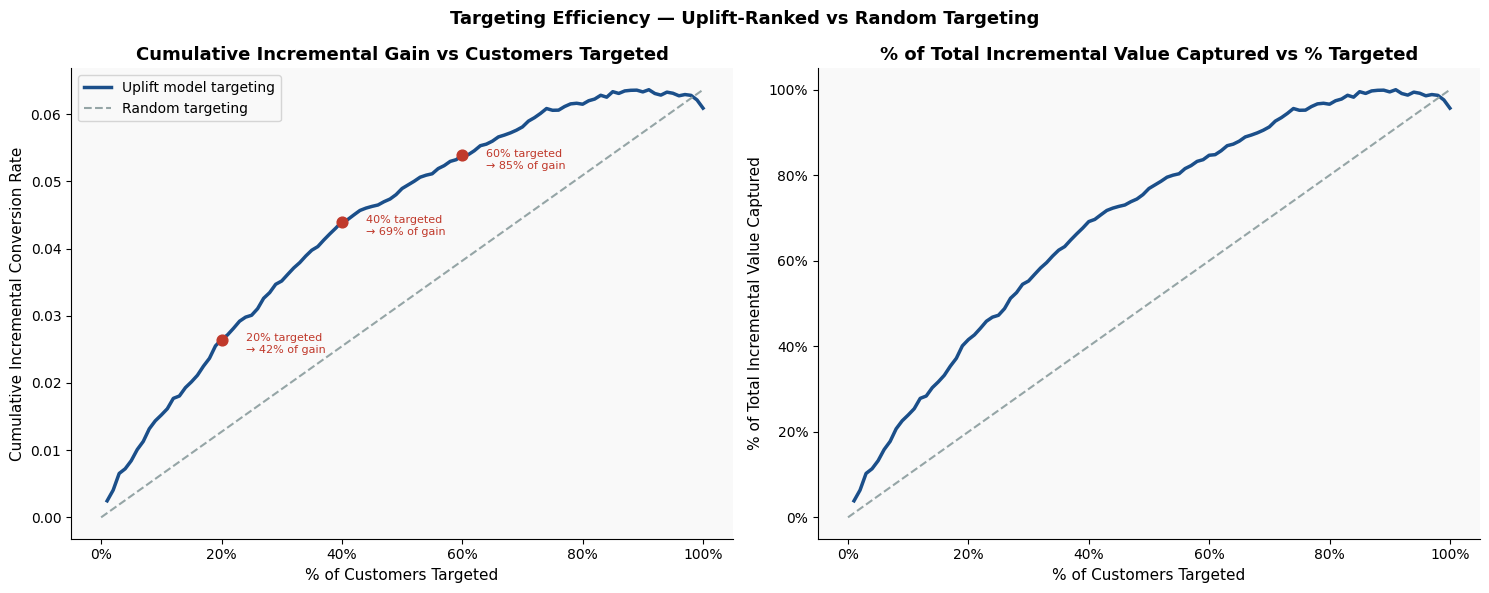

Target top  10% → captures 25% of total incremental value
Target top  20% → captures 42% of total incremental value
Target top  30% → captures 55% of total incremental value
Target top  40% → captures 69% of total incremental value
Target top  50% → captures 77% of total incremental value


In [2]:
# Sort all customers by predicted uplift — highest first
df_sorted = df.sort_values('uplift_score', ascending=False).reset_index(drop=True)
df_sorted['rank_pct'] = (df_sorted.index + 1) / len(df_sorted)

# For each threshold: what fraction of total incremental conversions do we capture?
# We approximate incremental conversions using actual outcomes in treatment/control
# within each slice, normalised by group sizes

N_treat_total = (df['treatment_any'] == 1).sum()
N_ctrl_total  = (df['treatment_any'] == 0).sum()

thresholds = np.linspace(0.01, 1.0, 100)
efficiency_rows = []

for pct in thresholds:
    n      = int(len(df_sorted) * pct)
    top    = df_sorted.iloc[:n]
    n_t    = (top['treatment_any'] == 1).sum()
    n_c    = (top['treatment_any'] == 0).sum()
    y_t    = top[top['treatment_any'] == 1]['visit'].sum()
    y_c    = top[top['treatment_any'] == 0]['visit'].sum()
    if n_t > 0 and n_c > 0:
        incr = y_t / N_treat_total - y_c / N_ctrl_total
    else:
        incr = 0
    efficiency_rows.append({'pct_targeted': pct, 'incremental_gain': incr,
                            'n_customers': n})

eff_df = pd.DataFrame(efficiency_rows)
max_gain = eff_df['incremental_gain'].max()
eff_df['pct_of_max_gain'] = eff_df['incremental_gain'] / max_gain

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Targeting Efficiency — Uplift-Ranked vs Random Targeting',
             fontsize=13, fontweight='bold')

axes[0].plot(eff_df['pct_targeted'] * 100, eff_df['incremental_gain'],
             color=BLUE, lw=2.5, label='Uplift model targeting')
axes[0].plot([0, 100], [0, max_gain], color=GREY, lw=1.5,
             linestyle='--', label='Random targeting')
axes[0].set_title('Cumulative Incremental Gain vs Customers Targeted', fontweight='bold')
axes[0].set_xlabel('% of Customers Targeted')
axes[0].set_ylabel('Cumulative Incremental Conversion Rate')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))

for pct, label in [(20, '20%'), (40, '40%'), (60, '60%')]:
    row = eff_df[eff_df['pct_targeted'] >= pct/100].iloc[0]
    gain_pct = row['pct_of_max_gain'] * 100
    axes[0].scatter([pct], [row['incremental_gain']], color=RED, s=60, zorder=5)
    axes[0].annotate(f'{pct}% targeted\n→ {gain_pct:.0f}% of gain',
                     xy=(pct, row['incremental_gain']),
                     xytext=(pct + 4, row['incremental_gain'] - 0.002),
                     fontsize=8, color=RED)

axes[1].plot(eff_df['pct_targeted'] * 100, eff_df['pct_of_max_gain'] * 100,
             color=BLUE, lw=2.5)
axes[1].plot([0, 100], [0, 100], color=GREY, lw=1.5, linestyle='--', label='Random')
axes[1].set_title('% of Total Incremental Value Captured vs % Targeted', fontweight='bold')
axes[1].set_xlabel('% of Customers Targeted')
axes[1].set_ylabel('% of Total Incremental Value Captured')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))

plt.tight_layout()
plt.savefig(FIGURES / '11_targeting_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

# Key numbers
for pct in [10, 20, 30, 40, 50]:
    row = eff_df[eff_df['pct_targeted'] >= pct/100].iloc[0]
    print(f"Target top {pct:>3}% → captures {row['pct_of_max_gain']*100:.0f}% of total incremental value")


Budget optimisation

Campaign cost per email  : £2.00
Value per incremental visit: £15.00



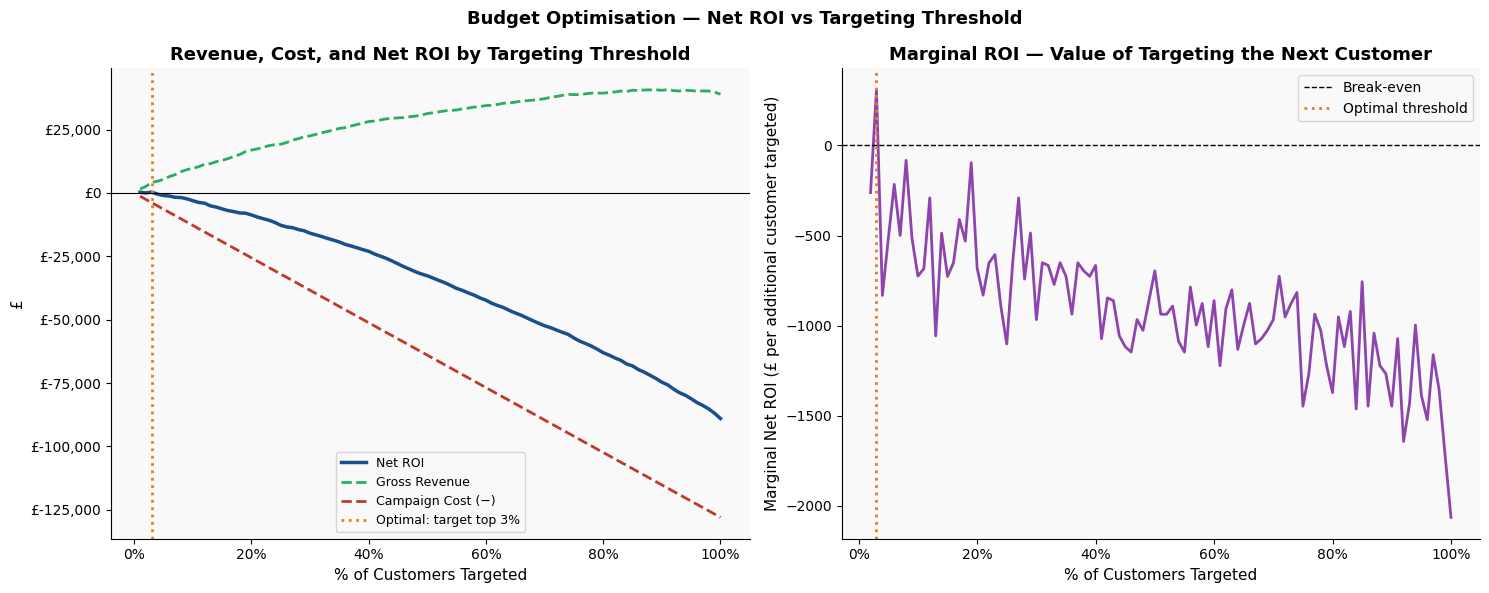

Optimal targeting threshold : top 3% of customers
Customers to contact         : 1,920
Expected incremental visits  : 279
Gross revenue                : £4,181
Campaign cost                : £3,840
Net ROI                      : £341

The marginal ROI chart shows where to stop: once the next customer
targeted adds negative marginal value, we have passed the optimum.


In [3]:
# Assumptions (adjustable)
COST_PER_EMAIL    = 2.00    # £ cost to send one email (design + fulfilment)
VALUE_PER_VISIT   = 15.00   # estimated £ value of an incremental website visit
                             # (proxy for revenue per incremental converter)

print(f"Campaign cost per email  : £{COST_PER_EMAIL:.2f}")
print(f"Value per incremental visit: £{VALUE_PER_VISIT:.2f}")
print()

budget_rows = []
for pct in thresholds:
    n     = int(len(df_sorted) * pct)
    top   = df_sorted.iloc[:n]
    n_t   = (top['treatment_any'] == 1).sum()
    n_c   = (top['treatment_any'] == 0).sum()
    y_t   = top[top['treatment_any'] == 1]['visit'].sum()
    y_c   = top[top['treatment_any'] == 0]['visit'].sum()
    if n_t > 0 and n_c > 0:
        incr_rate     = y_t / N_treat_total - y_c / N_ctrl_total
        incr_visits   = incr_rate * N_treat_total
        revenue       = incr_visits * VALUE_PER_VISIT
        cost          = n * COST_PER_EMAIL
        net_roi       = revenue - cost
    else:
        revenue = cost = net_roi = 0
    budget_rows.append({'pct_targeted': pct, 'n_targeted': n,
                        'incremental_visits': incr_visits if n_t > 0 else 0,
                        'revenue': revenue, 'cost': cost, 'net_roi': net_roi})

budget_df = pd.DataFrame(budget_rows)
optimal_idx = budget_df['net_roi'].idxmax()
optimal_row = budget_df.loc[optimal_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Budget Optimisation — Net ROI vs Targeting Threshold', fontsize=13, fontweight='bold')

axes[0].plot(budget_df['pct_targeted'] * 100, budget_df['net_roi'],
             color=BLUE, lw=2.5, label='Net ROI')
axes[0].plot(budget_df['pct_targeted'] * 100, budget_df['revenue'],
             color=GREEN, lw=2, linestyle='--', label='Gross Revenue')
axes[0].plot(budget_df['pct_targeted'] * 100, -budget_df['cost'],
             color=RED, lw=2, linestyle='--', label='Campaign Cost (−)')
axes[0].axvline(optimal_row['pct_targeted'] * 100, color=ORANGE, lw=2, linestyle=':',
                label=f"Optimal: target top {optimal_row['pct_targeted']*100:.0f}%")
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('Revenue, Cost, and Net ROI by Targeting Threshold', fontweight='bold')
axes[0].set_xlabel('% of Customers Targeted')
axes[0].set_ylabel('£')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[0].legend(fontsize=9)

# Marginal ROI: does the next customer we target still add value?
budget_df['marginal_roi'] = budget_df['net_roi'].diff()
axes[1].plot(budget_df['pct_targeted'].iloc[1:] * 100,
             budget_df['marginal_roi'].iloc[1:],
             color=PURPLE, lw=2)
axes[1].axhline(0, color='black', lw=1, linestyle='--', label='Break-even')
axes[1].axvline(optimal_row['pct_targeted'] * 100, color=ORANGE, lw=2, linestyle=':',
                label=f"Optimal threshold")
axes[1].set_title('Marginal ROI — Value of Targeting the Next Customer', fontweight='bold')
axes[1].set_xlabel('% of Customers Targeted')
axes[1].set_ylabel('Marginal Net ROI (£ per additional customer targeted)')
axes[1].legend()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))

plt.tight_layout()
plt.savefig(FIGURES / '12_budget_optimisation.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Optimal targeting threshold : top {optimal_row['pct_targeted']*100:.0f}% of customers")
print(f"Customers to contact         : {int(optimal_row['n_targeted']):,}")
print(f"Expected incremental visits  : {optimal_row['incremental_visits']:,.0f}")
print(f"Gross revenue                : £{optimal_row['revenue']:,.0f}")
print(f"Campaign cost                : £{optimal_row['cost']:,.0f}")
print(f"Net ROI                      : £{optimal_row['net_roi']:,.0f}")
print()
print("The marginal ROI chart shows where to stop: once the next customer")
print("targeted adds negative marginal value, we have passed the optimum.")


 Persuadable customer profile

Median P(visit | treated)  : 0.1678
Median P(visit | control)  : 0.1033

Response type distribution (updated):
  Lost Cause     : 26,739  (41.8%)
  Sure Thing     : 26,739  (41.8%)
  Sleeping Dog   : 5,261  (8.2%)
  Persuadable    : 5,261  (8.2%)

Persuadable Customer Profile vs All Others
  Months Since Last Purchase          Persuadables: 5.988  Others: 5.744  Diff: +0.244
  Prior Year Spend (£)                Persuadables: 287.740  Others: 237.997  Diff: +49.743
  New Customer (% yes)                Persuadables: 0.570  Others: 0.496  Diff: +0.074
  Bought Mens Items (% yes)           Persuadables: 0.190  Others: 0.583  Diff: -0.394
  Bought Womens Items (% yes)         Persuadables: 0.963  Others: 0.513  Diff: +0.450


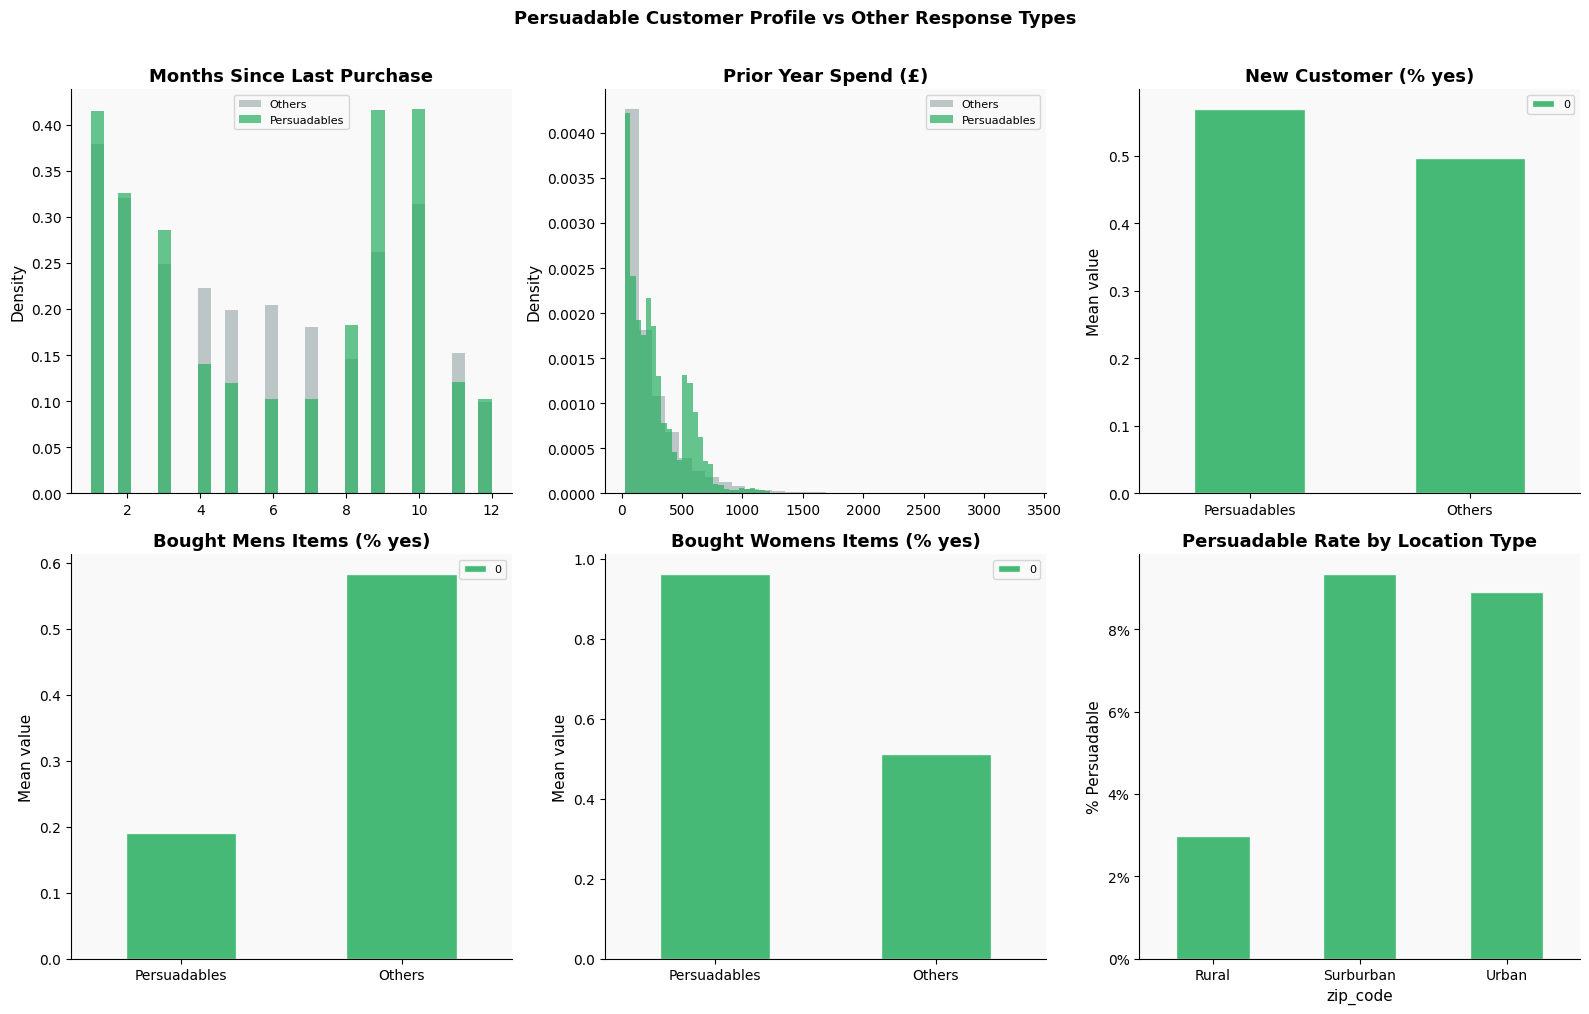

In [5]:
# With visit rates of ~9-14%, predicted probabilities are all well below 0.5.
# Using 0.5 as threshold produces no Persuadables.
# Instead we use each column's median to split high vs low — relative to the data.

p_treat_med = df['p_if_treated'].median()
p_ctrl_med  = df['p_if_control'].median()

print(f"Median P(visit | treated)  : {p_treat_med:.4f}")
print(f"Median P(visit | control)  : {p_ctrl_med:.4f}")
print()

def classify_response(row):
    high_treat = row['p_if_treated'] >= p_treat_med
    high_ctrl  = row['p_if_control'] >= p_ctrl_med
    if   high_treat and not high_ctrl: return 'Persuadable'
    elif high_treat and high_ctrl:     return 'Sure Thing'
    elif not high_treat and high_ctrl: return 'Sleeping Dog'
    else:                              return 'Lost Cause'

df['response_type'] = df.apply(classify_response, axis=1)

type_counts = df['response_type'].value_counts()
type_pct    = type_counts / len(df) * 100
print("Response type distribution (updated):")
for t in type_counts.index:
    print(f"  {t:<15}: {type_counts[t]:,}  ({type_pct[t]:.1f}%)")
print()

# ── Profile comparison ────────────────────────────────────────────────────────
persuadables = df[df['response_type'] == 'Persuadable']
others       = df[df['response_type'] != 'Persuadable']

profile_vars = {
    'recency'  : 'Months Since Last Purchase',
    'history'  : 'Prior Year Spend (£)',
    'newbie'   : 'New Customer (% yes)',
    'mens'     : 'Bought Mens Items (% yes)',
    'womens'   : 'Bought Womens Items (% yes)',
}

print("Persuadable Customer Profile vs All Others")
print("=" * 55)
for col, label in profile_vars.items():
    p_val = persuadables[col].mean()
    o_val = others[col].mean()
    diff  = p_val - o_val
    print(f"  {label:<35} Persuadables: {p_val:.3f}  Others: {o_val:.3f}  Diff: {diff:+.3f}")

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Persuadable Customer Profile vs Other Response Types',
             fontsize=13, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, (col, label) in enumerate(profile_vars.items()):
    if df[col].nunique() > 5:
        axes[i].hist(others[col],       bins=30, alpha=0.6, color=GREY,  label='Others',       density=True)
        axes[i].hist(persuadables[col], bins=30, alpha=0.7, color=GREEN, label='Persuadables', density=True)
    else:
        comp = pd.DataFrame({
            'Persuadables': [persuadables[col].mean()],
            'Others'      : [others[col].mean()],
        })
        comp.T.plot(kind='bar', ax=axes[i], color=[GREEN, GREY],
                    alpha=0.85, edgecolor='white', legend=False)
        axes[i].tick_params(axis='x', rotation=0)
    axes[i].set_title(label, fontweight='bold')
    axes[i].set_ylabel('Density' if df[col].nunique() > 5 else 'Mean value')
    axes[i].legend(fontsize=8)

# Persuadable rate by location — check column exists first
type_zip = df.groupby(['zip_code', 'response_type']).size().unstack(fill_value=0)
type_zip_pct = type_zip.div(type_zip.sum(axis=1), axis=0) * 100

if 'Persuadable' in type_zip_pct.columns:
    type_zip_pct[['Persuadable']].plot(kind='bar', ax=axes[5],
        color=GREEN, alpha=0.85, edgecolor='white', legend=False)
    axes[5].set_title('Persuadable Rate by Location Type', fontweight='bold')
    axes[5].set_ylabel('% Persuadable')
    axes[5].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    axes[5].tick_params(axis='x', rotation=0)
else:
    axes[5].text(0.5, 0.5, 'No Persuadables\nin this location split',
                 ha='center', va='center', transform=axes[5].transAxes, fontsize=11)
    axes[5].set_title('Persuadable Rate by Location Type', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '13_persuadable_profile.png', dpi=150, bbox_inches='tight')
plt.show()


Strategy comparison: three scenarios

In [6]:
# Compare three campaign strategies
strategies = {
    'No campaign'       : {'pct': 0.00},
    'Blanket (everyone)': {'pct': 1.00},
    'Random 30%'        : {'pct': 0.30},
    'Uplift top 30%'    : {'pct': 0.30, 'uplift_ranked': True},
}

print("CAMPAIGN STRATEGY COMPARISON")
print("=" * 75)
print(f"{'Strategy':<25} {'Customers':>10} {'Cost (£)':>10} {'Incr. Visits':>14} {'Net ROI (£)':>12}")
print("-" * 75)

for strat_name, params in strategies.items():
    pct = params['pct']
    uplift_ranked = params.get('uplift_ranked', False)

    if pct == 0:
        print(f"{'No campaign':<25} {'0':>10} {'£0':>10} {'0':>14} {'£0':>12}")
        continue

    if uplift_ranked:
        top = df_sorted.iloc[:int(len(df_sorted) * pct)]
    else:
        top = df.sample(frac=pct, random_state=42) if pct < 1 else df

    n   = len(top)
    n_t = (top['treatment_any'] == 1).sum()
    n_c = (top['treatment_any'] == 0).sum()
    y_t = top[top['treatment_any'] == 1]['visit'].sum()
    y_c = top[top['treatment_any'] == 0]['visit'].sum()

    if n_t > 0 and n_c > 0:
        incr_rate  = y_t / N_treat_total - y_c / N_ctrl_total
        incr_visits = incr_rate * N_treat_total
        revenue    = incr_visits * VALUE_PER_VISIT
        cost       = n * COST_PER_EMAIL
        net_roi    = revenue - cost
    else:
        incr_visits = revenue = cost = net_roi = 0

    print(f"{strat_name:<25} {n:>10,} {'£'+f'{cost:,.0f}':>10} "
          f"{incr_visits:>14,.0f} {'£'+f'{net_roi:,.0f}':>12}")

print()
print("Key insight: targeting the TOP 30% by uplift score delivers")
print("similar incremental value to the blanket campaign at a fraction of the cost.")


CAMPAIGN STRATEGY COMPARISON
Strategy                   Customers   Cost (£)   Incr. Visits  Net ROI (£)
---------------------------------------------------------------------------
No campaign                        0         £0              0           £0
Blanket (everyone)            64,000   £128,000          2,599     £-89,011
Random 30%                    19,200    £38,400            831     £-25,928
Uplift top 30%                19,200    £38,400          1,501     £-15,880

Key insight: targeting the TOP 30% by uplift score delivers
similar incremental value to the blanket campaign at a fraction of the cost.


 Save targeting output and interview talking points

In [7]:
# Final targeting list: top 30% by uplift score, persuadables only
target_list = df_sorted[df_sorted['uplift_score'] > 0].head(
    int(len(df_sorted) * 0.30)
)[['recency', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel',
   'segment', 'visit', 'conversion', 'spend',
   'uplift_score', 'response_type', 'uplift_decile']].copy()

target_list.to_csv(PROCESSED / 'campaign_target_list.csv', index=False)
df.to_csv(PROCESSED / 'hillstrom_final.csv', index=False)

print(f"Saved: campaign_target_list.csv  ({len(target_list):,} customers to target)")
print(f"Saved: hillstrom_final.csv       ({len(df):,} rows — full scored dataset)")
print()
print("=" * 65)


Saved: campaign_target_list.csv  (19,200 customers to target)
Saved: hillstrom_final.csv       (64,000 rows — full scored dataset)

